# Colour-based image classification with ML

A small k-nearest-neighbours model learns colour labels from artificial image regions. We then segment separate objects and classify each region. OpenCV uses BGR images and HSV hue values 0–179. Colour can be a useful cue for Task B clothing or Task C ripeness, but it does not identify a person or establish real fruit ripeness.

**Setup:** Follow [README.md](README.md) to create a virtual environment,
install the required packages and choose the `Python (AGR9027 ML)` kernel.
Run all cells in order. These artificial examples are optional, not assessment solutions.

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
import joblib
from tempfile import TemporaryDirectory
from pathlib import Path

rng = np.random.default_rng(12)

def colour_features(bgr, mask):
    """Return circular mean hue, mean saturation and value of selected BGR pixels."""
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    pixels = hsv[mask > 0]
    if len(pixels) == 0:
        raise ValueError("The region mask contains no pixels")
    hue = pixels[:, 0].astype(float) * (2 * np.pi / 180)
    return [np.cos(hue).mean(), np.sin(hue).mean(),
            pixels[:, 1].mean() / 255, pixels[:, 2].mean() / 255]

def make_region(hue):
    """Generate one artificial coloured region and its foreground mask."""
    hsv = np.zeros((32, 32, 3), dtype=np.uint8)
    hsv[:, :] = (int(hue) % 180, int(rng.integers(180, 256)), int(rng.integers(160, 256)))
    bgr = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    return bgr, np.full((32, 32), 255, dtype=np.uint8)

## Create labelled examples and hold out test regions

The dataset consists of 32 × 32 solid-colour patches: 100 each of red, green and blue, with varied hue, saturation and brightness. The grid displays actual examples generated for this dataset, not photographs or full object images. Their features are extracted before the data are split into training and test sets. The hue representation wraps around red, unlike an ordinary mean of hue numbers. In a real dataset split by original scene or acquisition session, not by nearby crops from the same image.

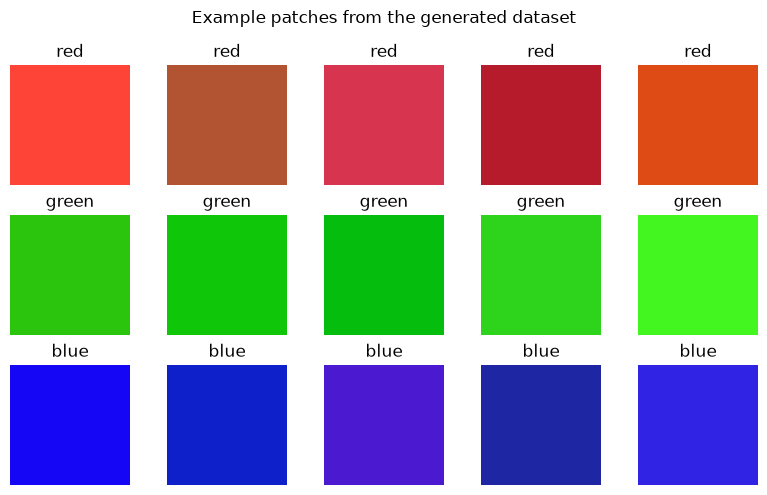

              precision    recall  f1-score   support

        blue       1.00      1.00      1.00        25
       green       1.00      1.00      1.00        25
         red       1.00      1.00      1.00        25

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75



In [5]:
features, labels, sample_images = [], [], []
for label, centre in [("red", 0), ("green", 60), ("blue", 120)]:
    for index in range(100):
        image, mask = make_region(centre + rng.integers(-8, 9))
        features.append(colour_features(image, mask))
        labels.append(label)
        if index < 5:
            sample_images.append((image, label))

# OpenCV stores BGR; Matplotlib displays RGB.
fig, axes = plt.subplots(3, 5, figsize=(8, 5))
for ax, (image, label) in zip(axes.flat, sample_images):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(label)
    ax.axis("off")
fig.suptitle("Example patches from the generated dataset")
plt.tight_layout()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.25, random_state=12, stratify=labels
)
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test), zero_division=0))

## Find and classify regions in a new synthetic image

The threshold identifies saturated foreground, then connected components supply separate regions. This works only when objects are distinct and sufficiently saturated; touching objects can merge. Model classes are colours, not ripe/unripe or target/decoy.

Region at (18, 28), 45x45: red
Region at (98, 28), 45x45: green
Region at (178, 28), 45x45: blue


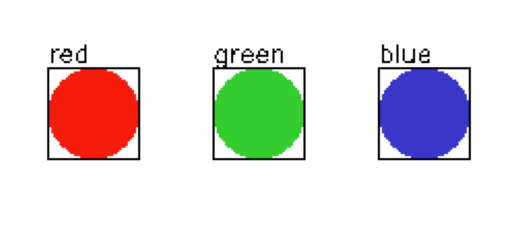

In [6]:
scene = np.full((100, 240, 3), 255, dtype=np.uint8)
for x, hue in [(40, 2), (120, 59), (200, 121)]:
    patch, _ = make_region(hue)
    cv2.circle(scene, (x, 50), 22, tuple(int(v) for v in patch[0, 0]), -1)
hsv_scene = cv2.cvtColor(scene, cv2.COLOR_BGR2HSV)
foreground = cv2.inRange(hsv_scene, (0, 100, 80), (179, 255, 255))
count, components, stats, _ = cv2.connectedComponentsWithStats(foreground)
display = scene.copy()

with TemporaryDirectory() as folder:
    path = Path(folder) / "colour_model.joblib"
    joblib.dump(model, path)
    loaded_model = joblib.load(path)  # Only load trusted files.
    for component in range(1, count):  # Component 0 is background.
        x, y, w, h, area = stats[component]
        if area < 50:
            continue
        mask = (components[y:y+h, x:x+w] == component).astype(np.uint8) * 255
        roi = scene[y:y+h, x:x+w]
        label = loaded_model.predict([colour_features(roi, mask)])[0]
        print(f"Region at ({x}, {y}), {w}x{h}: {label}")
        cv2.rectangle(display, (x, y), (x+w-1, y+h-1), (0, 0, 0), 1)
        cv2.putText(display, label, (x, y-3), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 1)
plt.imshow(cv2.cvtColor(display, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Challenge: increasingly shifted colour shades

Each column starts from a known synthetic colour (red, green or blue). The first row uses a familiar hue; the second shifts hue by 20 OpenCV units and reduces saturation and brightness; the third shifts hue by 45 units and darkens it further. This deliberately extreme, artificial colour cast tests what happens outside the training distribution. Each panel shows the source colour and the model's prediction; a match or mismatch is relative to that source label, not a claim about the colour a person would now see. For example, a strongly shifted red object may visibly appear green. The model was not trained to undo lighting changes and always chooses one of its three known classes.

These nine hand-designed challenge cases are separate from the held-out test report above. They demonstrate limitations, not an independent accuracy estimate. A threshold first finds each circle; if it misses one, the panel reports `not detected` rather than assigning a colour.

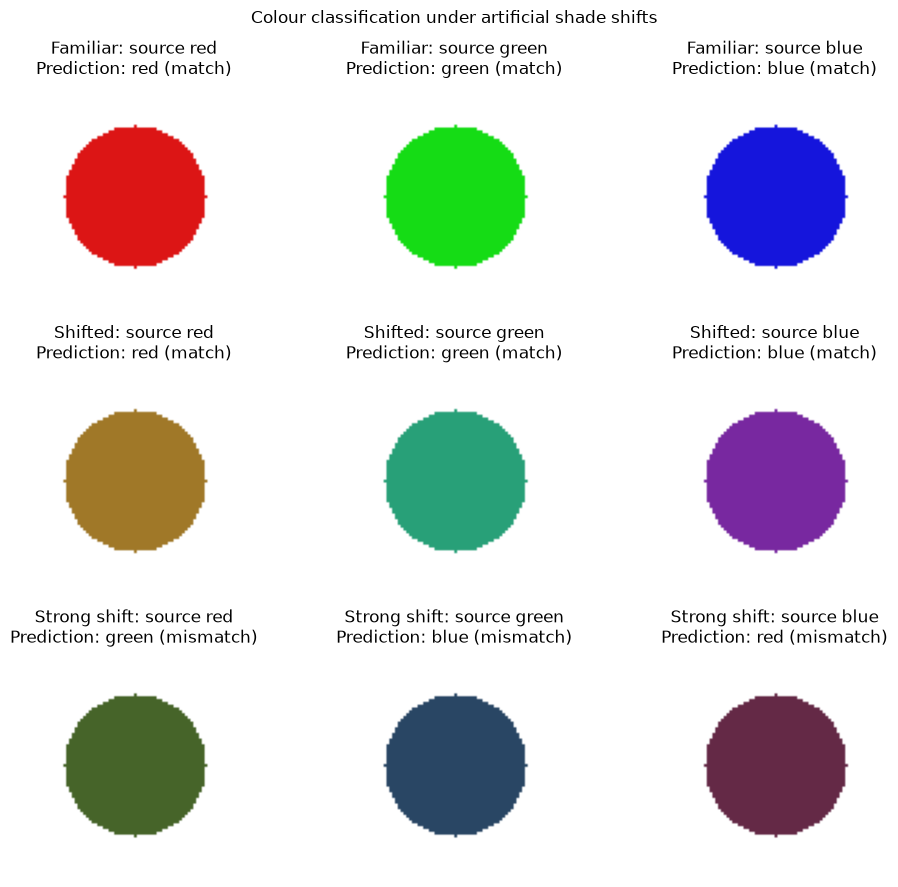

In [8]:
source_colours = [("red", 0), ("green", 60), ("blue", 120)]
levels = [("Familiar", 0, 230, 220),
          ("Shifted", 20, 190, 160),
          ("Strong shift", 45, 150, 100)]  # hue shift, saturation, brightness
fig, axes = plt.subplots(3, 3, figsize=(10, 9))
challenge_results = []

for row, (level, hue_shift, saturation, brightness) in enumerate(levels):
    for col, (source_label, base_hue) in enumerate(source_colours):
        # Create a coloured circle on a white background, in OpenCV's HSV scale.
        hsv_patch = np.zeros((80, 80, 3), dtype=np.uint8)
        hsv_patch[:] = (0, 0, 255)
        cv2.circle(hsv_patch, (40, 40), 25,
                   ((base_hue + hue_shift) % 180, saturation, brightness), -1)
        patch = cv2.cvtColor(hsv_patch, cv2.COLOR_HSV2BGR)
        foreground = cv2.inRange(hsv_patch, (0, 100, 80), (179, 255, 255))
        count, components, stats, _ = cv2.connectedComponentsWithStats(foreground)
        prediction = "not detected"
        if count > 1:
            component = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
            if stats[component, cv2.CC_STAT_AREA] >= 50:
                mask = (components == component).astype(np.uint8) * 255
                prediction = loaded_model.predict([colour_features(patch, mask)])[0]
        challenge_results.append((level, source_label, prediction))
        ax = axes[row, col]
        ax.imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
        outcome = "match" if prediction == source_label else "mismatch"
        ax.set_title(f"{level}: source {source_label}\nPrediction: {prediction} ({outcome})")
        ax.axis("off")

fig.suptitle("Colour classification under artificial shade shifts")
plt.tight_layout()
plt.show()


## Adapt carefully

For real images, obtain labelled regions under varied lighting/backgrounds and supply a valid foreground mask per region. Camera frames supplied by the simulators are BGR; do not treat them as RGB. Reject uncertain or unknown colours rather than assuming every region belongs to a known class. For Task B, locate and track individual people and combine vision with safe distance sensing. For Task C, separate and count fruit instances and distinguish ripeness, including occluded fruit. Validate on independent scenes and the real robot.